<a href="https://colab.research.google.com/github/halynazhabchyk/intro_to_pytorch/blob/main/Pytorch_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import numpy as np
torch.__version__

'2.9.0+cpu'

In [ ]:
torch.tensor([[1, -1], [1, -1]])

tensor([[ 1, -1],
        [ 1, -1]])

In [ ]:
torch.tensor(np.array([[1, 2, 3], [4, 5, 6]]))

tensor([[1, 2, 3],
        [4, 5, 6]])

torch.tensor()завжди копіює data. Якщо у вас є тензор dataі ви просто хочете змінити його requires_gradпрапорець, використовуйте requires_grad_()або , detach()щоб уникнути копіювання. Якщо у вас є масив numpy і ви хочете уникнути копіювання, використовуйте torch.as_tensor().

In [ ]:
x = torch.tensor([[1, 2, 3], [4, 5, 6]])
print(x[1][2])

tensor(6)


In [ ]:
x = torch.tensor([[1., -1.], [1., 1.]], requires_grad=True)
out = x.pow(2).sum()
out.backward()
x.grad

tensor([[ 2., -2.],
        [ 2.,  2.]])

Кожен тензор має пов'язаний об'єкт torch.Storage, який містить його дані. Клас тензора також забезпечує багатовимірне, покрокове представлення сховища та визначає числові операції над ним.

In [ ]:
scalar = torch.tensor(7)
scalar.ndim

0

In [ ]:
vector = torch.arange ( start = 0 , end = 10 , step = 1 )
torch.matmul(vector, vector)


tensor(285)

In [ ]:
torch.ones_like(vector)

tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [ ]:
tensor_A  =  torch.tensor ([[ 1 , 2 ], [ 3 , 4 ], [ 5 , 6 ]], dtype = torch.float32 )
tensor_B = torch.tensor ([ [ 7 , 10 ] , [ 8 , 11 ] , [ 9 , 12 ] ] , dtype = torch.float32 )
torch.matmul ( tensor_A , tensor_B.T )

tensor([[ 27.,  30.,  33.],
        [ 61.,  68.,  75.],
        [ 95., 106., 117.]])


Нейронні мережі повні множення матриць та скалярних добутків.



In [ ]:
print(torch.manual_seed(43))
linear = torch.nn.Linear(in_features=3, out_features= 6)
x = tensor_A.T
outpt = linear(x)
print(f"Input shape: {x.shape}\n")
print(f"Output:\n{outpt}\n\nOutput shape: {outpt.shape}")



Input shape: torch.Size([2, 3])

Output:
tensor([[ 1.7184, -4.1849, -0.4227, -0.1871,  0.1517, -0.8565],
        [ 1.8010, -5.2471, -0.5330,  0.0419,  0.2558, -0.9610]],
       grad_fn=<AddmmBackward0>)

Output shape: torch.Size([2, 6])


Знаходження мінімуму, максимуму, середнього значення, суми тощо (агрегування)

In [ ]:
# Stack tensors on top of each other
x_stacked = torch.stack([x, x, x, x], dim=1) # try changing dim to dim=1 and see what happens
x_stacked

tensor([[[1., 3., 5.],
         [1., 3., 5.],
         [1., 3., 5.],
         [1., 3., 5.]],

        [[2., 4., 6.],
         [2., 4., 6.],
         [2., 4., 6.],
         [2., 4., 6.]]])

In [ ]:
# Check for GPU
import torch
from torch import nn
# Налаштування агностичного коду пристрою device = "cuda" if torch.cuda.is_available() else "cpu" print(f"Використовується пристрій: {device}")

In [ ]:
what_were_covering = {1: "дані (підготовка та завантаження)",
                      2: "побудова моделі",
                      3: "підгонка моделі до даних (навчання)",
                      4: "створення прогнозів та оцінка моделі (висновок)",
                      5: "збереження та завантаження моделі",
                      6: "складання всього разом" }

In [ ]:
weights = 0.2
bias = 0.3

start = 0
step = 0.02
end = 1
X = torch.arange(start, end, step).unsqueeze(dim=1)
print(X)
y = X * weights + bias
print(y)




tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800],
        [0.2000],
        [0.2200],
        [0.2400],
        [0.2600],
        [0.2800],
        [0.3000],
        [0.3200],
        [0.3400],
        [0.3600],
        [0.3800],
        [0.4000],
        [0.4200],
        [0.4400],
        [0.4600],
        [0.4800],
        [0.5000],
        [0.5200],
        [0.5400],
        [0.5600],
        [0.5800],
        [0.6000],
        [0.6200],
        [0.6400],
        [0.6600],
        [0.6800],
        [0.7000],
        [0.7200],
        [0.7400],
        [0.7600],
        [0.7800],
        [0.8000],
        [0.8200],
        [0.8400],
        [0.8600],
        [0.8800],
        [0.9000],
        [0.9200],
        [0.9400],
        [0.9600],
        [0.9800]])
tensor([[0.3000],
        [0.3040],
        [0.3080],
        [0.3120],
        [0.3160],
        [

In [ ]:
train_split = int(len(X)* 0.8)
X_train ,  y_train = X[:train_split], y[:train_split]
X_test ,  y_test = X[train_split:], y[train_split:]
len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

In [ ]:
import matplotlib.pyplot as plt


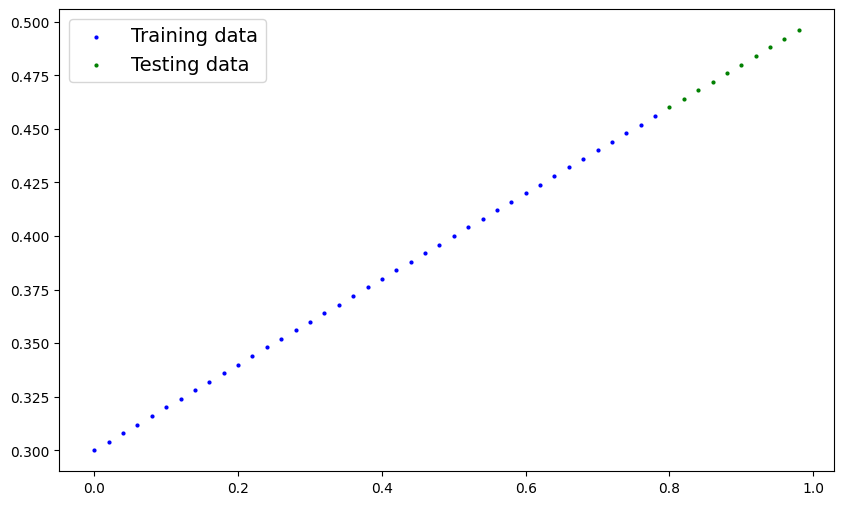

In [ ]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
  plt.figure(figsize = (10, 6))
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")

    # Plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")


  if predictions is not None:
    # Plot the predictions in red (predictions were made on the test data)
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  # Show the legend
  plt.legend(prop={"size": 14})
  plt.show()
plot_predictions()


In [ ]:
class LinearRegressionModel(nn.Module):
  def __init__(self):
     super().__init__()
     self.weights = nn.Parameter(torch.randn(1, dtype= torch.float, requires_grad=True))
     self.bias = nn.Parameter(torch.randn(1, dtype= torch.float, requires_grad=True))
  def forward(self, x: torch.Tensor) -> torch.tensor:
    return self.weights * x + self.bias

In [ ]:
torch.manual_seed(42)
model_0 = LinearRegressionModel()
loss_fun = nn.MSELoss()
optimizer = torch.optim.SGD(params= model_0.parameters(), lr = 0.01)

In [ ]:

epochs = 100
train_loss_values = []
test_loss_values = []
epoch_count = []


for epoch in range(epochs):

  model_0.train()
  y_pred = model_0(X_train)

  loss = loss_fun(y_pred, y_train)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model_0.eval()
  with torch.inference_mode():
    test_pred = model_0(X_test)
    test_loss = loss_fun(test_pred, y_test.type(torch.float))


    if epoch % 10 == 0:
      epoch_count.append(epoch)
      train_loss_values.append(loss.detach().numpy())
      test_loss_values.append(test_loss.detach().numpy())
      print(f"Epoch: {epoch} | MAE Train Loss: {loss} | MAE Test Loss: {test_loss} ")




Epoch: 0 | MAE Train Loss: 0.01489188801497221 | MAE Test Loss: 0.002223669085651636 
Epoch: 10 | MAE Train Loss: 0.009914025664329529 | MAE Test Loss: 0.0004583233967423439 
Epoch: 20 | MAE Train Loss: 0.00678953668102622 | MAE Test Loss: 7.485017704311758e-05 
Epoch: 30 | MAE Train Loss: 0.004824504256248474 | MAE Test Loss: 0.0003903131000697613 
Epoch: 40 | MAE Train Loss: 0.003584881080314517 | MAE Test Loss: 0.0010135057382285595 
Epoch: 50 | MAE Train Loss: 0.0027991768438369036 | MAE Test Loss: 0.0017279178136959672 
Epoch: 60 | MAE Train Loss: 0.0022975823376327753 | MAE Test Loss: 0.002420190256088972 
Epoch: 70 | MAE Train Loss: 0.0019738778937608004 | MAE Test Loss: 0.0030367320869117975 
Epoch: 80 | MAE Train Loss: 0.0017616208642721176 | MAE Test Loss: 0.003557563526555896 
Epoch: 90 | MAE Train Loss: 0.0016192516777664423 | MAE Test Loss: 0.003980806563049555 


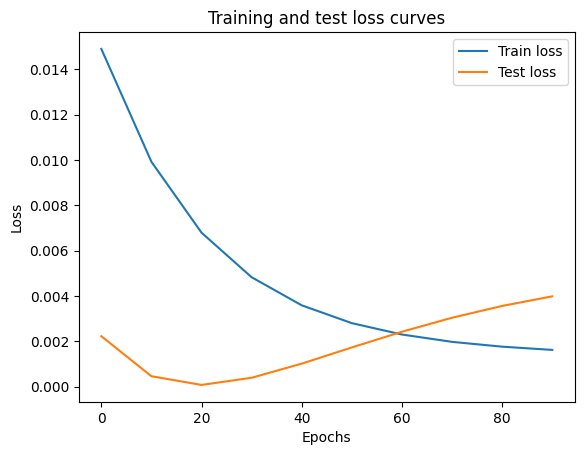

In [ ]:
plt.plot(epoch_count, train_loss_values, label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();


In [ ]:
from pathlib import Path

In [ ]:
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_NAME ="01_pytorch_workflow_model_0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj = model_0.state_dict(), f = MODEL_SAVE_PATH)


Saving model to: models/01_pytorch_workflow_model_0.pth


In [ ]:
# Check the saved file path
!ls -l models/01_pytorch_workflow_model_0.pth

-rw-r--r-- 1 root root 2117 Dec 29 14:30 models/01_pytorch_workflow_model_0.pth


In [ ]:
# Instantiate a new instance of our model (this will be instantiated with random weights)
loaded_model_0 = LinearRegressionModel()

# Load the state_dict of our saved model (this will update the new instance of our model with trained weights)
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

<All keys matched successfully>

In [ ]:
loaded_model_0.eval()
with torch.inference_mode():
  loaded_pred = loaded_model_0(X_test)

In [ ]:
# Compare previous model predictions with loaded model predictions (these should be the same)
test_pred == loaded_pred

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

In [ ]:
# # Setup device agnostic code
# device = "cuda" if torch.cuda.is_available() else "cpu"
# print(f"Using device: {device}")

In [ ]:
# # Check model device
# next(model_1.parameters()).device
# # Set model to GPU if it's available, otherwise it'll default to CPU
# model_1.to(device) # the device variable was set above to be "cuda" if available or "cpu" if not
# next(model_1.parameters()).device

ДЗ

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
weights = 0.3
bias = 0.9
X = torch.arange(0,1, 0.006).unsqueeze(dim = 1)
y = X * weights + bias
print(f"Number of X samples: {len(X)}")
print(f"Number of y samples: {len(y)}")
print(f"First 10 X & y samples:\nX: {X[:10]}\ny: {y[:10]}")


Number of X samples: 167
Number of y samples: 167
First 10 X & y samples:
X: tensor([[0.0000],
        [0.0060],
        [0.0120],
        [0.0180],
        [0.0240],
        [0.0300],
        [0.0360],
        [0.0420],
        [0.0480],
        [0.0540]])
y: tensor([[0.9000],
        [0.9018],
        [0.9036],
        [0.9054],
        [0.9072],
        [0.9090],
        [0.9108],
        [0.9126],
        [0.9144],
        [0.9162]])


In [ ]:
X_train = X[:int(len(X)* 0.8)]
X_test = X[int(len(X)* 0.8):]
y_train = y[:int(len(y)* 0.8)]
y_test = y[int(len(y)* 0.8):]
len(X_train),len(y_train),len(X_test),len(y_test)

(133, 133, 34, 34)

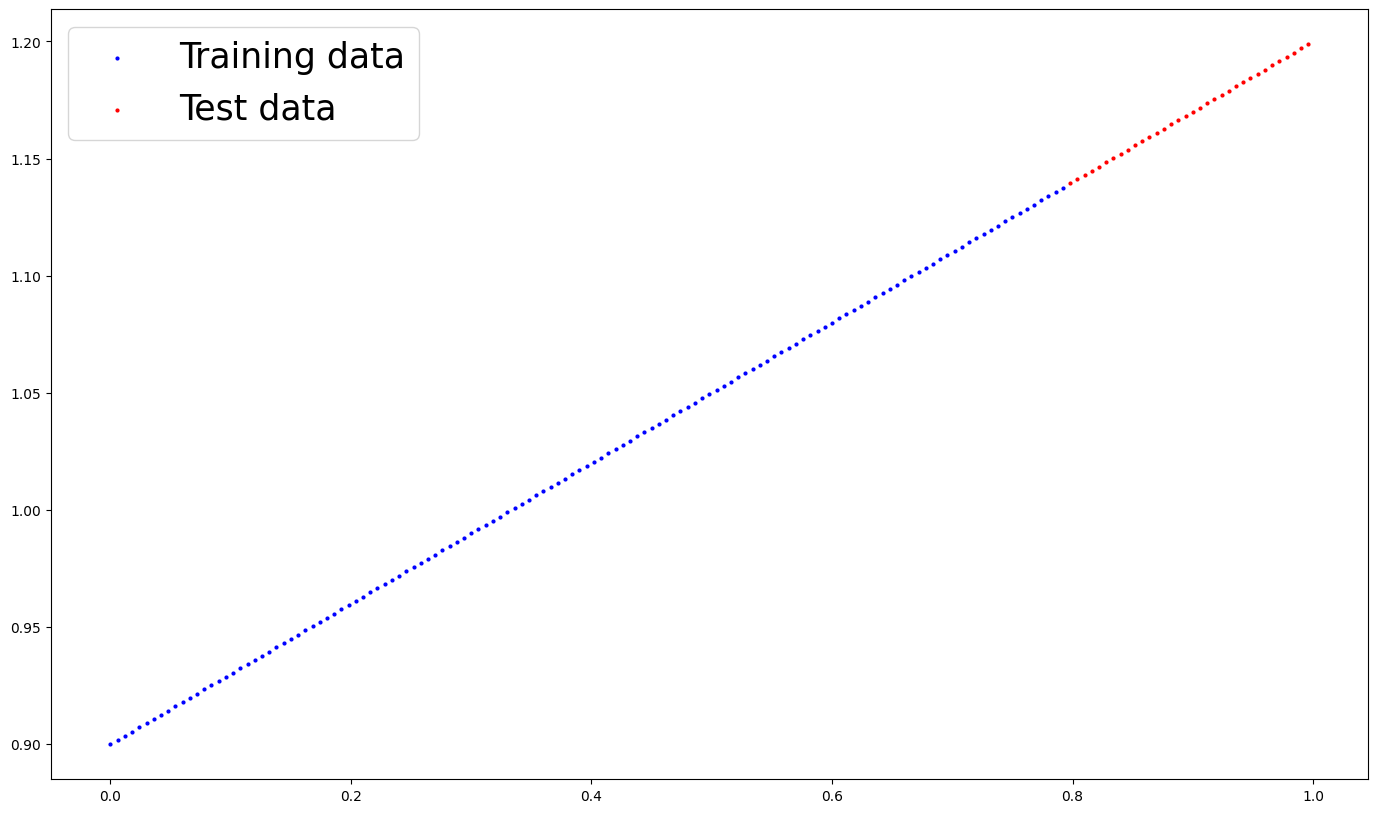

In [ ]:
def plot_predictions_dz(train_data, train_labels, test_data, test_labels, predictions = None):
  plt.figure(figsize=(17,10))
  plt.scatter(train_data, train_labels, c = 'b', marker ='o', s = 4, label = 'Training data')
  plt.scatter(test_data, test_labels, c = 'r', marker ='o', s = 4, label = 'Test data')

  if predictions is not None:
    plt.scatter(test_data, predictions, c = 'g', marker ='o', s = 4, label = 'Predictions')
  plt.legend(prop = {"size" : 25})
  plt.show()

plot_predictions_dz(X_train, y_train, X_test, y_test)




In [ ]:
class LinearRegressionModel_dz(nn.Module):
  def __init__(self):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(1, dtype= torch.float, requires_grad= True))
    self.bias = nn.Parameter(torch.randn(1, dtype= torch.float, requires_grad= True))
  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.weights * x + self.bias




In [ ]:

torch.manual_seed(42)
model_dz = LinearRegressionModel()
model_dz.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [ ]:
next(model_dz.parameters()).device
model_dz.to(device)

LinearRegressionModel()

In [ ]:
list(model_dz.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
loss_func = nn.L1Loss()
optimizer = torch.optim.SGD(params= model_dz.parameters(), lr = 0.01)


In [ ]:
epochs = 300
train_loss_values = []
test_loss_values = []
epoch_count = []

X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

for epoch in range(epochs):
  model_dz.train()

  y_pred_tr = model_dz(X_train)

  loss = loss_fun(y_pred_tr, y_train)

  optimizer.zero_grad()

  loss.backward()

  optimizer.step()


  if epoch % 20 == 0:
    model_dz.eval()
    with torch.inference_mode():
      y_pred = model_dz(X_test)
      test_loss = loss_fun(y_pred, y_test.type(torch.float))
      epoch_count.append(epoch)
      train_loss_values.append(loss.detach().numpy())
      test_loss_values.append(test_loss.detach().numpy())
      print(f"Epoch: {epoch} | Train loss: {loss:.3f} | Test loss: {test_loss:.3f}")






Epoch: 0 | Train loss: 0.001 | Test loss: 0.004
Epoch: 20 | Train loss: 0.001 | Test loss: 0.004
Epoch: 40 | Train loss: 0.001 | Test loss: 0.004
Epoch: 60 | Train loss: 0.001 | Test loss: 0.004
Epoch: 80 | Train loss: 0.001 | Test loss: 0.004
Epoch: 100 | Train loss: 0.001 | Test loss: 0.004
Epoch: 120 | Train loss: 0.001 | Test loss: 0.003
Epoch: 140 | Train loss: 0.001 | Test loss: 0.003
Epoch: 160 | Train loss: 0.001 | Test loss: 0.003
Epoch: 180 | Train loss: 0.001 | Test loss: 0.003
Epoch: 200 | Train loss: 0.001 | Test loss: 0.003
Epoch: 220 | Train loss: 0.001 | Test loss: 0.003
Epoch: 240 | Train loss: 0.001 | Test loss: 0.003
Epoch: 260 | Train loss: 0.001 | Test loss: 0.003
Epoch: 280 | Train loss: 0.001 | Test loss: 0.003


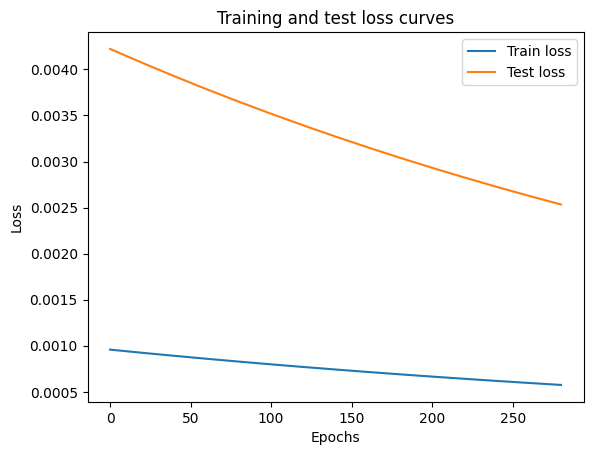

In [ ]:
plt.plot(epoch_count, train_loss_values, label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test loss curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();


In [ ]:
model_dz.eval()

with torch.inference_mode():
  y_preds = model_dz(X_test)
y_preds

tensor([[1.2068],
        [1.2097],
        [1.2126],
        [1.2154],
        [1.2183],
        [1.2211],
        [1.2240],
        [1.2268],
        [1.2297],
        [1.2326],
        [1.2354],
        [1.2383],
        [1.2411],
        [1.2440],
        [1.2468],
        [1.2497],
        [1.2525],
        [1.2554],
        [1.2583],
        [1.2611],
        [1.2640],
        [1.2668],
        [1.2697],
        [1.2725],
        [1.2754],
        [1.2783],
        [1.2811],
        [1.2840],
        [1.2868],
        [1.2897],
        [1.2925],
        [1.2954],
        [1.2982],
        [1.3011]])

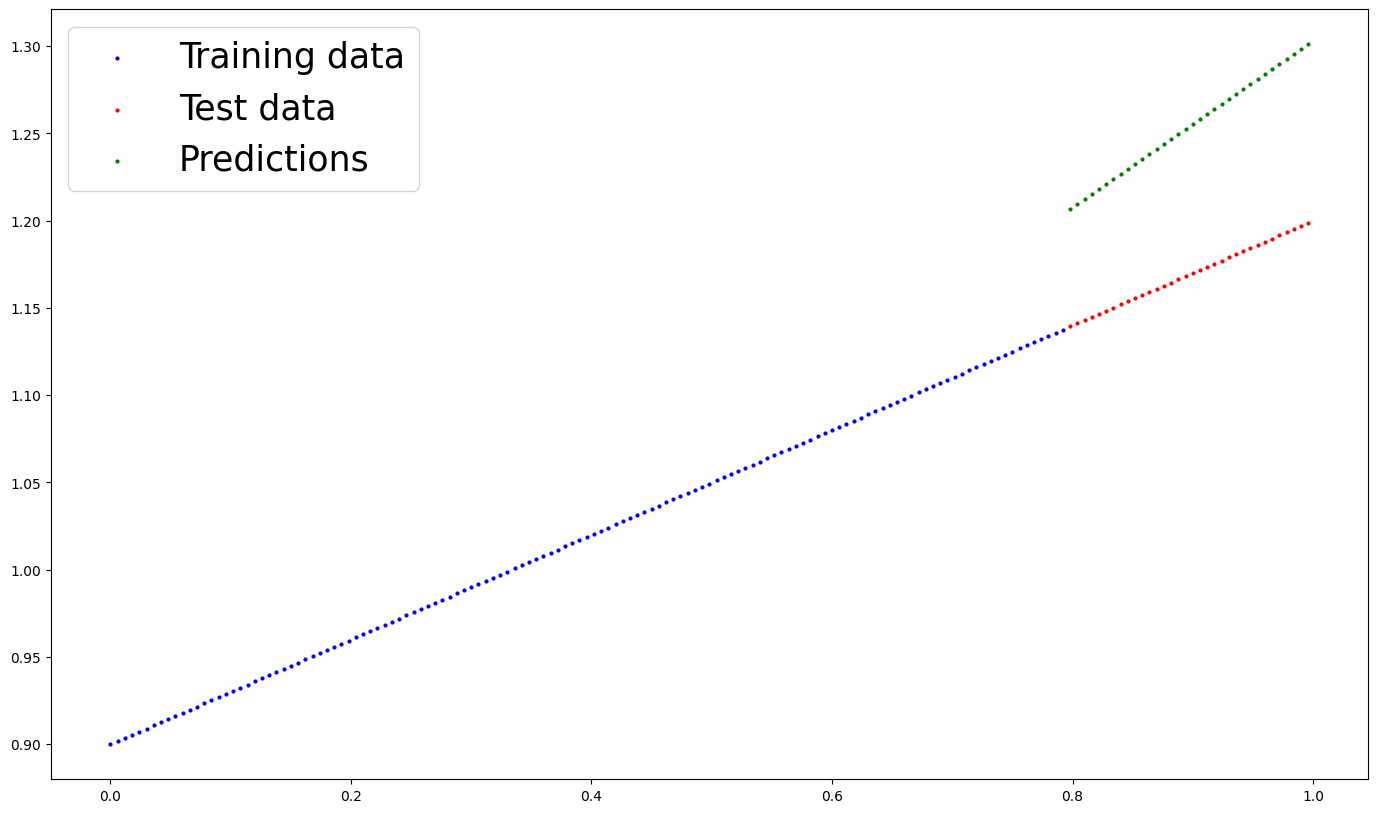

In [ ]:
plot_predictions_dz(X_train, y_train, X_test, y_test, predictions= y_preds)

In [ ]:
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents = True,exist_ok = True)
# 2. Create model save path
MODEL_NAME = "pytorch_model_dz"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME
# 3. Save the model state dict
print(f"Saving model to {MODEL_SAVE_PATH}")
torch.save(obj = model_dz.state_dict(),f = MODEL_SAVE_PATH)

Saving model to models/pytorch_model_dz


In [ ]:
loaded_model_dz = LinearRegressionModel()
loaded_model_dz.load_state_dict(torch.load(f = MODEL_SAVE_PATH))
loaded_model_dz.to(device)

LinearRegressionModel()

In [ ]:
y_pred_loaded = loaded_model_dz(X_test)
y_pred_loaded == y_preds


tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

Chepter 02

In [ ]:
from sklearn.datasets import make_circles
n_samples = 1000
X, y = make_circles(n_samples, noise = 0.04, random_state = 42)

In [ ]:
print(f"First 5 X features:\n{X[:5]}")
print(f"\nFirst 5 y labels:\n{y[:5]}")

First 5 X features:
[[ 0.74822656  0.23908325]
 [-0.74509559  0.16097526]
 [-0.82262532  0.19762051]
 [-0.41143316  0.68255648]
 [ 0.44390494 -0.89582949]]

First 5 y labels:
[1 1 1 1 0]


In [ ]:
import pandas as pd
circles = pd.DataFrame({"X1":X[:, 0], "X2":X[:, 1], "label":y})
circles.head(5)

,X1,X2,label
0,0.748227,0.239083,1
1,-0.745096,0.160975,1
2,-0.822625,0.197621,1
3,-0.411433,0.682556,1
4,0.443905,-0.895829,0


In [ ]:
circles.label.value_counts()

,count
label,
1,500
0,500


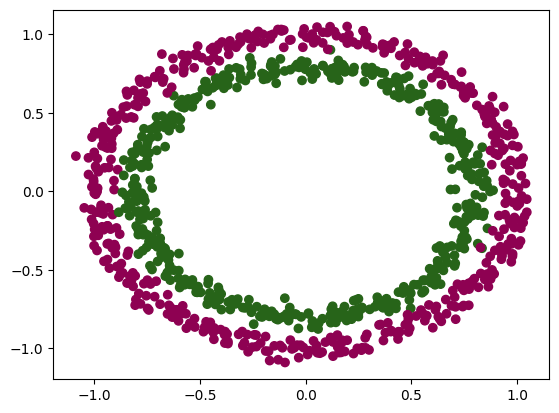

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(x = X[:, 0], y = X[:, 1], c = y, cmap = plt.cm.PiYG)

In [ ]:
# Check the shapes of our features and labels
X.shape, y.shape
# View the first example of features and labels
X_sample = X[0]
y_sample = y[0]
print(f"Values for one sample of X: {X_sample} and the same for y: {y_sample}")
print(f"Shapes for one sample of X: {X_sample.shape} and the same for y: {y_sample.shape}")

Values for one sample of X: [0.74822656 0.23908325] and the same for y: 1
Shapes for one sample of X: (2,) and the same for y: ()


In [ ]:
import torch
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

# View the first five samples
X[:5], y[:5]

(tensor([[ 0.7482,  0.2391],
         [-0.7451,  0.1610],
         [-0.8226,  0.1976],
         [-0.4114,  0.6826],
         [ 0.4439, -0.8958]]),
 tensor([1., 1., 1., 1., 0.]))

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42)
len(X_train), len(X_test), len(y_train), len(y_test)

(800, 200, 800, 200)

In [ ]:
# Standard PyTorch imports
import torch
from torch import nn

# Make device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
# 1. Construct a model class that subclasses nn.Module
class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()
        # 2. Create 2 nn.Linear layers capable of handling X and y input and output shapes
        self.layer_1 = nn.Linear(in_features=2, out_features=5) # takes in 2 features (X), produces 5 features
        self.layer_2 = nn.Linear(in_features=5, out_features=1) # takes in 5 features, produces 1 feature (y)

    # 3. Define a forward method containing the forward pass computation
    def forward(self, x):
        # Return the output of layer_2, a single feature, the same shape as y
        return self.layer_2(self.layer_1(x)) # computation goes through layer_1 first then the output of layer_1 goes through layer_2

# 4. Create an instance of the model and send it to target device
model_0 = CircleModelV0().to(device)
model_0

CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)

In [ ]:
# Make predictions with the model
untrained_preds = model_0(X_test.to(device))
print(f"Length of predictions: {len(untrained_preds)}, Shape: {untrained_preds.shape}")
print(f"Length of test samples: {len(y_test)}, Shape: {y_test.shape}")
print(f"\nFirst 10 predictions:\n{untrained_preds[:10]}")
print(f"\nFirst 10 test labels:\n{y_test[:10]}")

Length of predictions: 200, Shape: torch.Size([200, 1])
Length of test samples: 200, Shape: torch.Size([200])

First 10 predictions:
tensor([[ 0.1510],
        [ 0.2549],
        [-0.0377],
        [ 0.2079],
        [ 0.0795],
        [ 0.1438],
        [ 0.3369],
        [ 0.3123],
        [-0.0472],
        [ 0.2597]], grad_fn=<SliceBackward0>)

First 10 test labels:
tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(params= model_0.parameters(), lr = 0.1)

In [ ]:
def accuracy_fn(y_true, y_pred):
  correct = torch.eq(y_true, y_pred).sum().item()
  acc = (correct/len(y_pred))*100
  return acc

In [ ]:
# View the frist 5 outputs of the forward pass on the test data
y_logits = model_0(X_test.to(device))[:5]
y_logits

tensor([[ 0.1510],
        [ 0.2549],
        [-0.0377],
        [ 0.2079],
        [ 0.0795]], grad_fn=<SliceBackward0>)

In [ ]:
# Use sigmoid on model logits
y_pred_probs = torch.sigmoid(y_logits)
y_pred_probs

tensor([[0.5377],
        [0.5634],
        [0.4906],
        [0.5518],
        [0.5199]], grad_fn=<SigmoidBackward0>)

In [ ]:
# Find the predicted labels (round the prediction probabilities)
y_preds = torch.round(y_pred_probs)

In [ ]:
torch.manual_seed(42)

# Set the number of epochs
epochs = 100

# Put data to target device
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# Build training and evaluation loop
for epoch in range(epochs):
    ### Training
    model_0.train()

    # 1. Forward pass (model outputs raw logits)
    y_logits = model_0(X_train).squeeze() # squeeze to remove extra `1` dimensions, this won't work unless model and data are on same device
    y_pred = torch.round(torch.sigmoid(y_logits)) # turn logits -> pred probs -> pred labls

    # 2. Calculate loss/accuracy
    # loss = loss_fn(torch.sigmoid(y_logits), # Using nn.BCELoss you need torch.sigmoid()
    #                y_train)
    loss = loss_fn(y_logits, # Using nn.BCEWithLogitsLoss works with raw logits
                   y_train)
    acc = accuracy_fn(y_true=y_train,
                      y_pred=y_pred)

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backwards
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

    ### Testing
    model_0.eval()
    with torch.inference_mode():
        # 1. Forward pass
        test_logits = model_0(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        # 2. Caculate loss/accuracy
        test_loss = loss_fn(test_logits,
                            y_test)
        test_acc = accuracy_fn(y_true=y_test,
                               y_pred=test_pred)

    # Print out what's happening every 10 epochs
    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")

Epoch: 0 | Loss: 0.69606, Accuracy: 53.62% | Test loss: 0.70200, Test acc: 49.00%
Epoch: 10 | Loss: 0.69467, Accuracy: 53.25% | Test loss: 0.70005, Test acc: 47.00%
Epoch: 20 | Loss: 0.69404, Accuracy: 52.25% | Test loss: 0.69901, Test acc: 47.00%
Epoch: 30 | Loss: 0.69374, Accuracy: 51.00% | Test loss: 0.69838, Test acc: 47.00%
Epoch: 40 | Loss: 0.69358, Accuracy: 51.12% | Test loss: 0.69797, Test acc: 47.00%
Epoch: 50 | Loss: 0.69348, Accuracy: 51.50% | Test loss: 0.69767, Test acc: 47.00%
Epoch: 60 | Loss: 0.69341, Accuracy: 51.00% | Test loss: 0.69743, Test acc: 46.50%
Epoch: 70 | Loss: 0.69336, Accuracy: 51.25% | Test loss: 0.69723, Test acc: 46.50%
Epoch: 80 | Loss: 0.69331, Accuracy: 50.88% | Test loss: 0.69706, Test acc: 46.00%
Epoch: 90 | Loss: 0.69328, Accuracy: 50.88% | Test loss: 0.69691, Test acc: 45.50%


In [ ]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

helper_functions.py already exists, skipping download


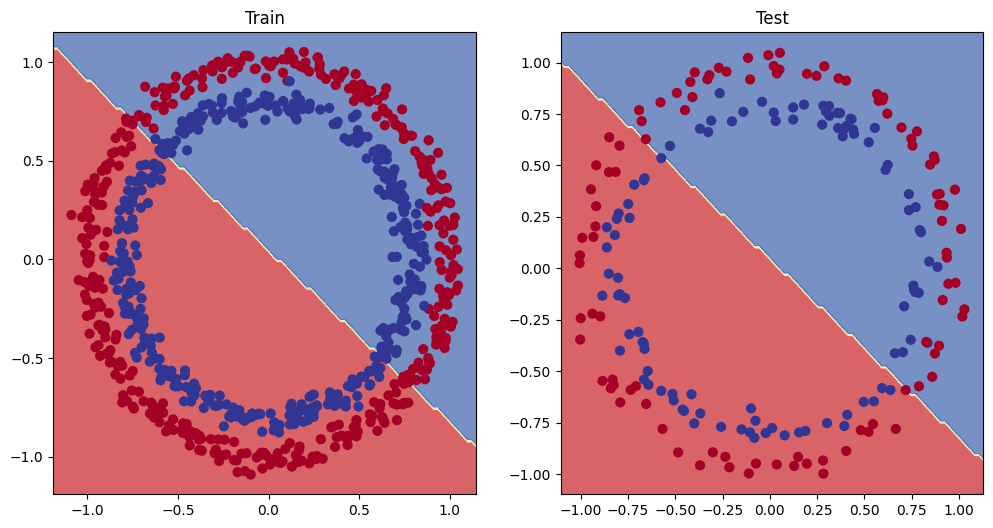

In [ ]:
from helper_functions import plot_predictions, plot_decision_boundary
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)

In [ ]:
class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10) # extra layer
        self.layer_3 = nn.Linear(in_features=10, out_features=1)

    def forward(self, x): # note: always make sure forward is spelt correctly!
        # Creating a model like this is the same as below, though below
        # generally benefits from speedups where possible.
        # z = self.layer_1(x)
        # z = self.layer_2(z)
        # z = self.layer_3(z)
        # return z
        return self.layer_3(self.layer_2(self.layer_1(x)))

model_1 = CircleModelV1().to(device)
model_1

CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [ ]:
# loss_fn = nn.BCELoss() # Requires sigmoid on input
loss_fn = nn.BCEWithLogitsLoss() # Does not require sigmoid on input
optimizer = torch.optim.SGD(model_1.parameters(), lr=0.1)

In [ ]:
torch.manual_seed(42)

epochs = 1000 # Train for longer

# Put data to target device
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

for epoch in range(epochs):
    ### Training
    # 1. Forward pass
    y_logits = model_1(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits)) # logits -> prediction probabilities -> prediction labels

    # 2. Calculate loss/accuracy
    loss = loss_fn(y_logits, y_train)
    acc = accuracy_fn(y_true=y_train,
                      y_pred=y_pred)

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backwards
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

    ### Testing
    model_1.eval()
    with torch.inference_mode():
        # 1. Forward pass
        test_logits = model_1(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))
        # 2. Caculate loss/accuracy
        test_loss = loss_fn(test_logits,
                            y_test)
        test_acc = accuracy_fn(y_true=y_test,
                               y_pred=test_pred)

    # Print out what's happening every 10 epochs
    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")


Epoch: 0 | Loss: 0.69394, Accuracy: 51.00% | Test loss: 0.69262, Test acc: 51.00%
Epoch: 100 | Loss: 0.69305, Accuracy: 50.38% | Test loss: 0.69379, Test acc: 49.00%
Epoch: 200 | Loss: 0.69299, Accuracy: 51.25% | Test loss: 0.69437, Test acc: 46.50%
Epoch: 300 | Loss: 0.69298, Accuracy: 51.25% | Test loss: 0.69457, Test acc: 45.50%
Epoch: 400 | Loss: 0.69298, Accuracy: 51.38% | Test loss: 0.69464, Test acc: 45.50%
Epoch: 500 | Loss: 0.69298, Accuracy: 51.38% | Test loss: 0.69466, Test acc: 45.50%
Epoch: 600 | Loss: 0.69298, Accuracy: 51.38% | Test loss: 0.69467, Test acc: 45.50%
Epoch: 700 | Loss: 0.69298, Accuracy: 51.38% | Test loss: 0.69467, Test acc: 45.50%
Epoch: 800 | Loss: 0.69298, Accuracy: 51.38% | Test loss: 0.69467, Test acc: 45.50%
Epoch: 900 | Loss: 0.69298, Accuracy: 51.38% | Test loss: 0.69467, Test acc: 45.50%


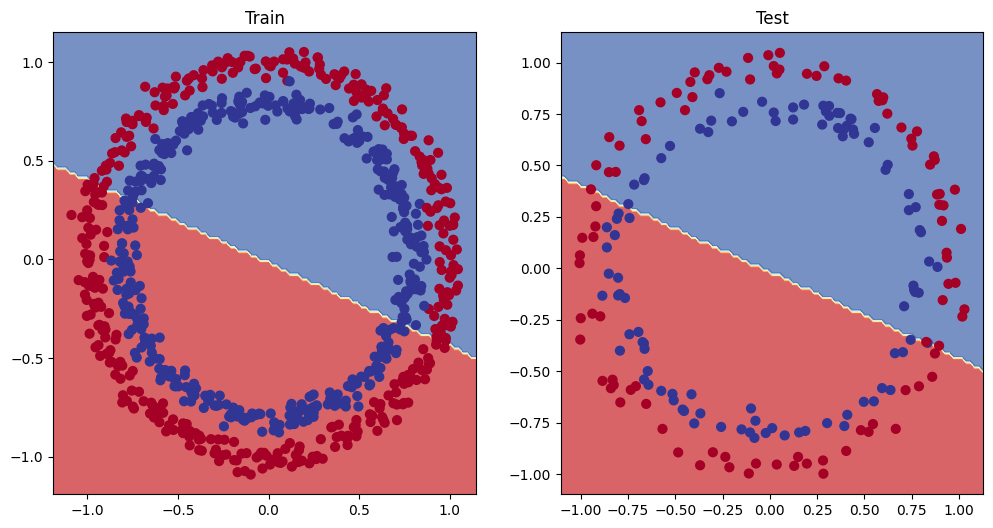

In [ ]:
# Plot decision boundaries for training and test sets
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_1, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_1, X_test, y_test)

In [ ]:
# Build model with non-linear activation function
from torch import nn
class CircleModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)
        self.relu = nn.ReLU() # <- add in ReLU activation function
        # Can also put sigmoid in the model
        # This would mean you don't need to use it on the predictions
        # self.sigmoid = nn.Sigmoid()

    def forward(self, x):
      # Intersperse the ReLU activation function between layers
       return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

model_3 = CircleModelV2().to(device)
print(model_3)

CircleModelV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)


In [ ]:
# Setup loss and optimizer
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_3.parameters(), lr=0.1)

In [ ]:
# Fit the model
torch.manual_seed(42)
epochs = 1000

# Put all data on target device
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

for epoch in range(epochs):
    # 1. Forward pass
    y_logits = model_3(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits)) # logits -> prediction probabilities -> prediction labels

    # 2. Calculate loss and accuracy
    loss = loss_fn(y_logits, y_train) # BCEWithLogitsLoss calculates loss using logits
    acc = accuracy_fn(y_true=y_train,
                      y_pred=y_pred)

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backward
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

    ### Testing
    model_3.eval()
    with torch.inference_mode():
      # 1. Forward pass
      test_logits = model_3(X_test).squeeze()
      test_pred = torch.round(torch.sigmoid(test_logits)) # logits -> prediction probabilities -> prediction labels
      # 2. Calculate loss and accuracy
      test_loss = loss_fn(test_logits, y_test)
      test_acc = accuracy_fn(y_true=y_test,
                             y_pred=test_pred)

    # Print out what's happening
    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Accuracy: {test_acc:.2f}%")

Epoch: 0 | Loss: 0.69295, Accuracy: 50.00% | Test Loss: 0.69324, Test Accuracy: 50.00%
Epoch: 100 | Loss: 0.69116, Accuracy: 52.62% | Test Loss: 0.69114, Test Accuracy: 53.00%
Epoch: 200 | Loss: 0.68976, Accuracy: 53.37% | Test Loss: 0.68957, Test Accuracy: 54.50%
Epoch: 300 | Loss: 0.68793, Accuracy: 53.12% | Test Loss: 0.68749, Test Accuracy: 55.00%
Epoch: 400 | Loss: 0.68522, Accuracy: 52.88% | Test Loss: 0.68452, Test Accuracy: 55.50%
Epoch: 500 | Loss: 0.68102, Accuracy: 53.12% | Test Loss: 0.68006, Test Accuracy: 56.50%
Epoch: 600 | Loss: 0.67519, Accuracy: 54.25% | Test Loss: 0.67384, Test Accuracy: 56.50%
Epoch: 700 | Loss: 0.66674, Accuracy: 58.50% | Test Loss: 0.66477, Test Accuracy: 59.00%
Epoch: 800 | Loss: 0.65172, Accuracy: 64.88% | Test Loss: 0.64977, Test Accuracy: 69.00%
Epoch: 900 | Loss: 0.62400, Accuracy: 74.12% | Test Loss: 0.62468, Test Accuracy: 78.00%


In [ ]:
from sklearn.datasets import make_blobs
X_blob, y_blob = make_blobs(n_samples = 1000,
                            n_features= 2, centers= 4,
                            cluster_std= 1.5, random_state= 42)


X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)
print(X_blob[:5], y_blob[:5])

tensor([[-8.4134,  6.9352],
        [-5.7665, -6.4312],
        [-6.0421, -6.7661],
        [ 3.9508,  0.6984],
        [ 4.2505, -0.2815]]) tensor([3, 2, 2, 1, 1])


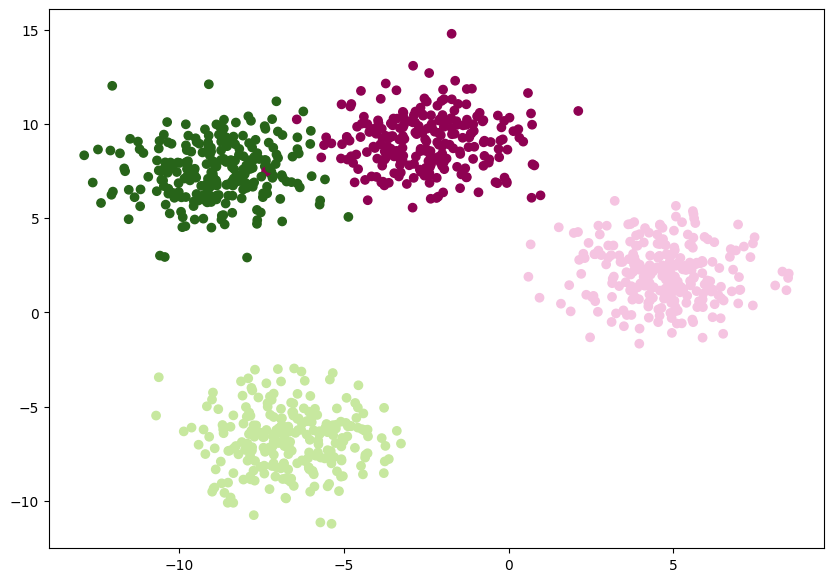

In [ ]:
X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob, y_blob, test_size = 0.2, random_state=42)
plt.figure(figsize=(10,7))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c = y_blob, cmap= plt.cm.PiYG )

In [ ]:
# Create device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 42

In [ ]:
from ast import Num
class BlobModel(nn.Module):
  def __init__(self, input_features, output_features, hidden_units = 8):
    super().__init__()
    self.linear_layer_stack = nn.Sequential(
        nn.Linear(in_features= input_features, out_features = hidden_units),
        nn.Linear(in_features= hidden_units, out_features = hidden_units),
        nn.ReLU(),
        nn.Linear(in_features= hidden_units, out_features = output_features)
    )

  def forward(self, x):
    return self.linear_layer_stack(x)


model_4 = BlobModel(input_features= NUM_FEATURES, output_features= NUM_CLASSES, hidden_units=8).to(device)
model_4



BlobModel(
  (linear_layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): Linear(in_features=8, out_features=8, bias=True)
    (2): ReLU()
    (3): Linear(in_features=8, out_features=4, bias=True)
  )
)

In [ ]:
# Create loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_4.parameters(),
                            lr=0.1) # exercise: try changing the learning rate here and seeing what happens to the model's performance

In [ ]:
model_4(X_blob_train.to(device))[:5]

tensor([[-0.8464, -0.5488, -1.5205, -1.1707],
        [ 0.0719, -0.8399, -0.7320, -0.3596],
        [ 1.0107, -0.0080,  0.3130, -0.6061],
        [ 0.7518, -0.0857,  0.4050, -0.1338],
        [ 0.1722, -0.5539, -0.3585, -0.2015]], grad_fn=<SliceBackward0>)

In [ ]:
model_4(X_blob_train.to(device))[0].shape, NUM_CLASSES

(torch.Size([4]), 4)

In [ ]:
# Fit the model
torch.manual_seed(42)

# Set number of epochs
epochs = 100

# Put data to target device
X_blob_train, y_blob_train = X_blob_train.to(device), y_blob_train.to(device)
X_blob_test, y_blob_test = X_blob_test.to(device), y_blob_test.to(device)


for epoch in range(epochs):
  model_4.train()
  y_logits = model_4(X_blob_train)
  y_pred = torch.softmax(y_logits, dim =1).argmax(dim=1)

  loss = loss_fn(y_logits, y_blob_train)
  acc = accuracy_fn(y_true= y_blob_train, y_pred=y_pred)

  optimizer.zero_grad()

  loss.backward()
  optimizer.step()

  model_4.eval()
  with torch.inference_mode():
    testing_logits = model_4(X_blob_test)
    test_pred = torch.softmax(test_logits, dim =1).argmax(dim =1)

    test_loss = loss_fn(test_logits, y_blob_test)
    test_acc = accuracy_fn(y_true= y_blob_test, y_pred = test_pred)
    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")




Epoch: 0 | Loss: 1.17696, Acc: 47.88% | Test Loss: 0.01707, Test Acc: 99.50%
Epoch: 10 | Loss: 0.29450, Acc: 99.25% | Test Loss: 0.01707, Test Acc: 99.50%
Epoch: 20 | Loss: 0.11140, Acc: 99.12% | Test Loss: 0.01707, Test Acc: 99.50%
Epoch: 30 | Loss: 0.06924, Acc: 99.00% | Test Loss: 0.01707, Test Acc: 99.50%
Epoch: 40 | Loss: 0.05333, Acc: 99.00% | Test Loss: 0.01707, Test Acc: 99.50%
Epoch: 50 | Loss: 0.04522, Acc: 99.00% | Test Loss: 0.01707, Test Acc: 99.50%
Epoch: 60 | Loss: 0.04038, Acc: 99.12% | Test Loss: 0.01707, Test Acc: 99.50%
Epoch: 70 | Loss: 0.03719, Acc: 99.12% | Test Loss: 0.01707, Test Acc: 99.50%
Epoch: 80 | Loss: 0.03495, Acc: 99.12% | Test Loss: 0.01707, Test Acc: 99.50%
Epoch: 90 | Loss: 0.03329, Acc: 99.12% | Test Loss: 0.01707, Test Acc: 99.50%


In [ ]:
print(testing_logits.shape)
print(test_pred.shape)
print(y_blob_test.shape)


torch.Size([200, 4])
torch.Size([200])
torch.Size([200])


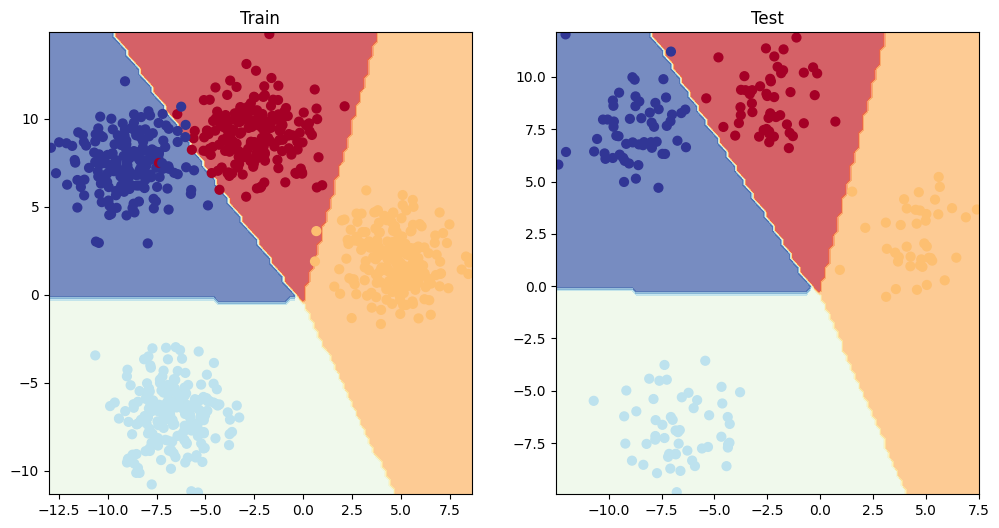

In [ ]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_4, X_blob_train, y_blob_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_4, X_blob_test, y_blob_test)

In [ ]:
print(y_preds.shape)
print(y_blob_test.shape)


torch.Size([5, 1])
torch.Size([200])


In [ ]:
from torchmetrics import Accuracy
torchmetrics_accuracy = Accuracy(task='multiclass', num_classes=4).to(device)

# Calculate accuracy
torchmetrics_accuracy(test_pred, y_blob_test)

tensor(0.9950)

In [ ]:
# Create device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
NUM_FEATURES = 2
RANDOM_SEED = 42
NUM_SAMPLES = 1000


In [ ]:
from sklearn.datasets import make_moons
import torch

X_moons, y_moons = make_moons(n_samples = NUM_SAMPLES, random_state= RANDOM_SEED, noise = 0.08)
X_moons = torch.from_numpy(X_moons).type(torch.float)
y_moons = torch.from_numpy(y_moons).type(torch.float)

X_moons[:5], y_moons[:5]

(tensor([[-0.0394,  0.4290],
         [ 1.0099, -0.4352],
         [ 0.8824, -0.3035],
         [ 0.3243, -0.4280],
         [-0.8368,  0.5333]]),
 tensor([1., 1., 1., 1., 0.]))

In [ ]:
import matplotlib.pyplot as plt

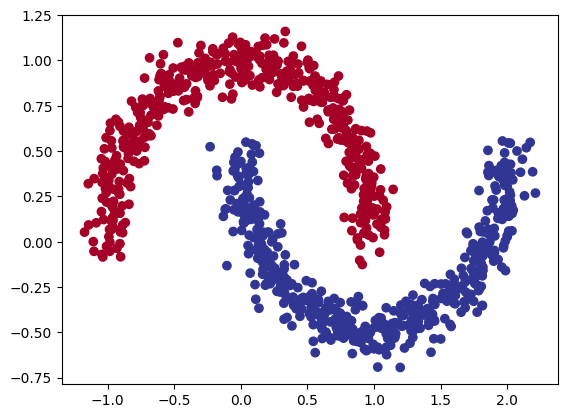

In [ ]:
plt.scatter(x = X_moons[:, 0], y = X_moons[:, 1],
            c = y_moons, cmap=plt.cm.RdYlBu)

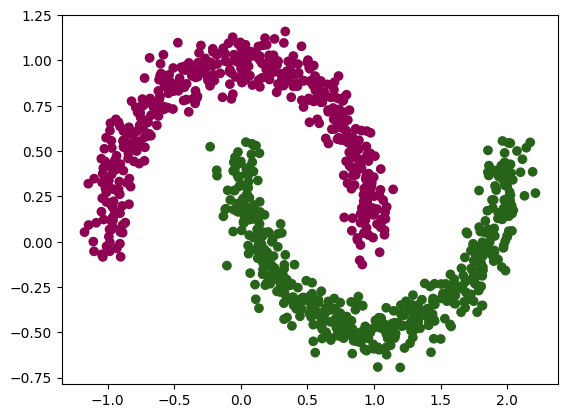

In [ ]:
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(X_moons, y_moons, test_size = 0.2, random_state=RANDOM_SEED)


plt.scatter(x = X_moons[:, 0], y = X_moons[:, 1], c = y_moons, cmap= plt.cm.PiYG)

In [ ]:
len(X_moons_train), len(X_moons_test), len(y_moons_train), len(y_moons_test)

(800, 200, 800, 200)

In [ ]:
from torch import nn

In [ ]:
class MoonModel(nn.Module):
  def __init__(self, input_features, output_features, hidden_units = 7):
     super().__init__()
     self.layer1 = nn.Linear(in_features=input_features,
                              out_features=hidden_units)
     self.layer2 = nn.Linear(in_features=hidden_units,
                              out_features=hidden_units)
     self.layer3 = nn.Linear(in_features=hidden_units,
                              out_features=output_features)
     self.relu = nn.ReLU()

  def forward(self, x):
      return self.layer3(self.relu(self.layer2(self.relu(self.layer1(x)))))






In [ ]:
model_dz = MoonModel(input_features= NUM_FEATURES, output_features=1,
                     hidden_units=7).to(device)
model_dz

MoonModel(
  (layer1): Linear(in_features=2, out_features=7, bias=True)
  (layer2): Linear(in_features=7, out_features=7, bias=True)
  (layer3): Linear(in_features=7, out_features=1, bias=True)
  (relu): ReLU()
)

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(params=model_dz.parameters(), # parameters of model to optimize
                            lr=0.1)


In [ ]:
! pip install  torchmetrics

In [ ]:
from torchmetrics import Accuracy

accuracy_metric = Accuracy(task="binary").to(device)

# функція для зручності
def accuracy_fn(y_true, y_pred):
    return accuracy_metric(y_true, y_pred)


In [ ]:
model_dz(X_moons_train).to(device)[:5]

tensor([[0.4650],
        [0.4854],
        [0.5109],
        [0.5162],
        [0.5323]], grad_fn=<SliceBackward0>)

In [ ]:
model_dz(X_moons_train).to(device)[0].shape

torch.Size([1])

In [ ]:
torch.manual_seed(42)
epochs = 1000

X_moons_train, y_moons_train = X_moons_train.to(device), y_moons_train.to(device)
X_moons_test, y_moons_test = X_moons_test.to(device), y_moons_test.to(device)

for epoch in range(epochs):
  model_dz.train()
  y_logits = model_dz(X_moons_train).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits))

  loss = loss_fn(y_logits, y_moons_train)
  acc = accuracy_fn(y_true= y_moons_train.int(), y_pred= y_pred.int())

  optimizer.zero_grad()

  loss.backward()

  optimizer.step()

  model_dz.eval()
  with torch.inference_mode():
    test_logits = model_dz(X_moons_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))

    test_loss = loss_fn(test_logits, y_moons_test)
    test_acc = accuracy_fn( y_true = y_moons_test.int(), y_pred= test_pred.int())


  if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")





Epoch: 0 | Loss: 0.73196, Accuracy: 0.50% | Test loss: 0.72829, Test acc: 0.50%
Epoch: 100 | Loss: 0.41619, Accuracy: 0.84% | Test loss: 0.42576, Test acc: 0.84%
Epoch: 200 | Loss: 0.25978, Accuracy: 0.88% | Test loss: 0.26020, Test acc: 0.87%
Epoch: 300 | Loss: 0.23119, Accuracy: 0.89% | Test loss: 0.22341, Test acc: 0.92%
Epoch: 400 | Loss: 0.21172, Accuracy: 0.90% | Test loss: 0.20133, Test acc: 0.92%
Epoch: 500 | Loss: 0.18342, Accuracy: 0.92% | Test loss: 0.17149, Test acc: 0.93%
Epoch: 600 | Loss: 0.14478, Accuracy: 0.94% | Test loss: 0.13167, Test acc: 0.95%
Epoch: 700 | Loss: 0.10311, Accuracy: 0.97% | Test loss: 0.09151, Test acc: 0.98%
Epoch: 800 | Loss: 0.07047, Accuracy: 0.98% | Test loss: 0.06031, Test acc: 1.00%
Epoch: 900 | Loss: 0.04958, Accuracy: 0.99% | Test loss: 0.04115, Test acc: 1.00%


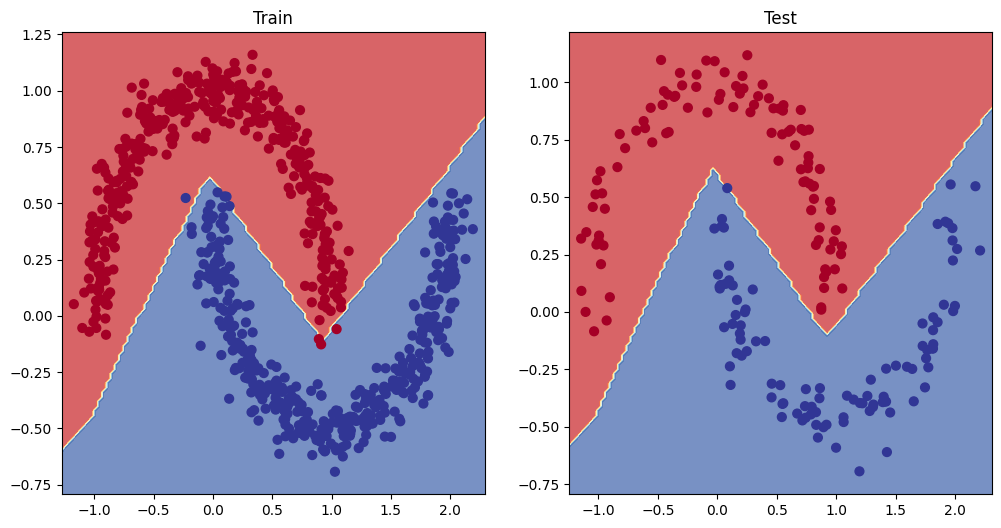

In [ ]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_dz, X_moons_train, y_moons_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_dz, X_moons_test, y_moons_test)

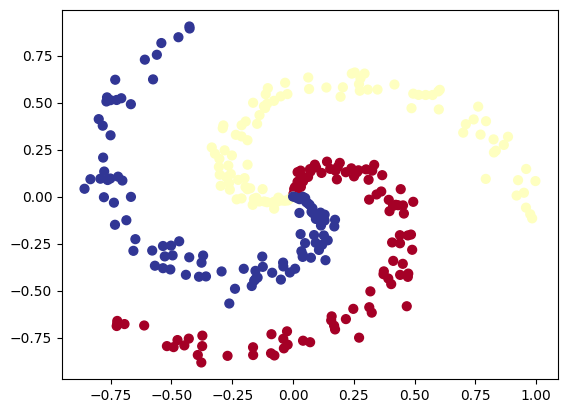

In [ ]:
import numpy as np
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
N = 100 # number of points per class
D = 2 # dimensionality
K = 3 # number of classes
X = np.zeros((N*K,D)) # data matrix (each row = single example)
y = np.zeros(N*K, dtype='uint8') # class labels
for j in range(K):
  ix = range(N*j,N*(j+1))
  r = np.linspace(0.0,1,N) # radius
  t = np.linspace(j*4,(j+1)*4,N) + np.random.randn(N)*0.2 # theta
  X[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
  y[ix] = j
# lets visualize the data
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.RdYlBu)
plt.show()

In [ ]:
X = torch.from_numpy(X).type(torch.float) # features as float32
y = torch.from_numpy(y).type(torch.LongTensor) # labels need to be of type long

# Create train and test splits
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_SEED)
len(X_train), len(X_test), len(y_train), len(y_test)

(240, 60, 240, 60)

In [ ]:
class SpiralModel(nn.Module):
  def __init__(self, input_features, output_features, hidden_units = 7):
     super().__init__()
     self.layer1 = nn.Linear(in_features=input_features,
                              out_features=hidden_units)
     self.layer2 = nn.Linear(in_features=hidden_units,
                              out_features=hidden_units)
     self.layer3 = nn.Linear(in_features=hidden_units,
                              out_features=output_features)
     self.relu = nn.ReLU()

  def forward(self, x):
      return self.layer3(self.relu(self.layer2(self.relu(self.layer1(x)))))



In [ ]:
model_1 = SpiralModel(input_features = 2, output_features=3, hidden_units= 7).to(device)
model_1

SpiralModel(
  (layer1): Linear(in_features=2, out_features=7, bias=True)
  (layer2): Linear(in_features=7, out_features=7, bias=True)
  (layer3): Linear(in_features=7, out_features=3, bias=True)
  (relu): ReLU()
)

In [ ]:
X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)
print(X_train.dtype, X_test.dtype, y_train.dtype, y_test.dtype)

torch.float32 torch.float32 torch.int64 torch.int64


In [ ]:
model_1(X_train).to(device)[0].size()

torch.Size([3])

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_1.parameters(),
                             lr=0.02)

In [ ]:
accuracy_metric = Accuracy(task="multiclass", num_classes= 3).to(device)

# функція для зручності
def accuracy_fn(y_true, y_pred):
    return accuracy_metric(y_true, y_pred)

In [ ]:
torch.manual_seed(42)
epochs = 1000

for epoch in range(epochs):
  y_logits = model_1(X_train)
  y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)

  loss = loss_fn(y_logits, y_train)
  acc = accuracy_fn(y_pred, y_train)

  # 3. optimizer zero grad
  optimizer.zero_grad()

  # 4. loss backwards
  loss.backward()

  # 5. optimizer step step step
  optimizer.step()


  model_1.eval()
  with torch.inference_mode():
    # 1. Forward pass
    test_logits = model_1(X_test)
    test_pred = torch.softmax(test_logits, dim=1).argmax(dim=1)
    # 2. Caculate loss and acc
    test_loss = loss_fn(test_logits, y_test)
    test_acc = accuracy_fn(test_pred, y_test)

  # Print out what's happening
  if epoch % 100 == 0:
    print(f"Epoch: {epoch} | Loss: {loss:.2f} Acc: {acc:.2f} | Test loss: {test_loss:.2f} Test acc: {test_acc:.2f}")



Epoch: 0 | Loss: 1.12 Acc: 0.32 | Test loss: 1.09 Test acc: 0.37
Epoch: 100 | Loss: 0.13 Acc: 0.98 | Test loss: 0.09 Test acc: 1.00
Epoch: 200 | Loss: 0.03 Acc: 0.99 | Test loss: 0.01 Test acc: 1.00
Epoch: 300 | Loss: 0.02 Acc: 0.99 | Test loss: 0.00 Test acc: 1.00
Epoch: 400 | Loss: 0.02 Acc: 0.99 | Test loss: 0.00 Test acc: 1.00
Epoch: 500 | Loss: 0.02 Acc: 0.99 | Test loss: 0.00 Test acc: 1.00
Epoch: 600 | Loss: 0.02 Acc: 0.99 | Test loss: 0.00 Test acc: 1.00
Epoch: 700 | Loss: 0.02 Acc: 0.99 | Test loss: 0.00 Test acc: 1.00
Epoch: 800 | Loss: 0.02 Acc: 0.99 | Test loss: 0.00 Test acc: 1.00
Epoch: 900 | Loss: 0.01 Acc: 0.99 | Test loss: 0.00 Test acc: 1.00


Lesson 3

In [ ]:
import torch
from torch import nn

import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt




In [ ]:
train_data = datasets.FashionMNIST(
    root = 'data', train = True,
    download=True, transform=ToTensor(),
    target_transform=None)

In [ ]:
# Setup testing data
test_data = datasets.FashionMNIST(
    root="data",
    train=False, # get test data
    download=True,
    transform=ToTensor()
)

In [ ]:
# See first training sample
image, label = train_data[0]
image, label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [ ]:
image.shape

torch.Size([1, 28, 28])

In [ ]:
# How many samples are there?
len(train_data.data), len(train_data.targets), len(test_data.data), len(test_data.targets)

(60000, 60000, 10000, 10000)

In [ ]:
# See classes
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

Image shape: torch.Size([1, 28, 28])


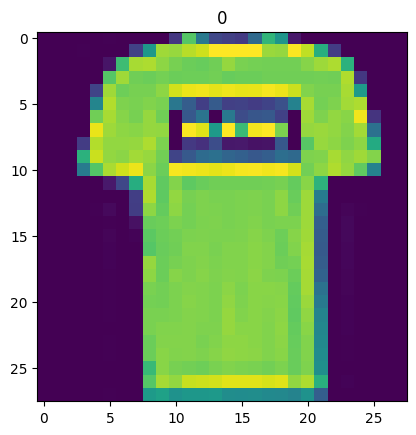

In [ ]:
image, label = train_data[1]
print(f"Image shape: {image.shape}")
plt.imshow(image.squeeze()) # image shape is [1, 28, 28] (colour channels, height, width)
plt.title(label);

Text(0.5, 1.0, 'T-shirt/top')

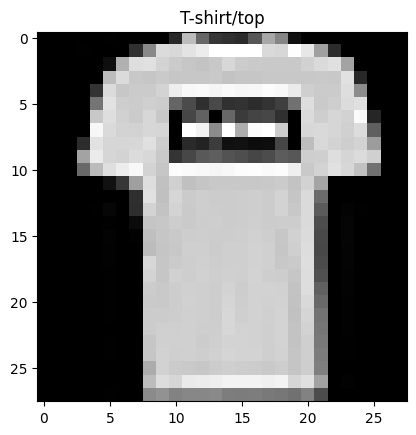

In [ ]:
plt.imshow(image.squeeze(), cmap= 'gray')
plt.title(class_names[label])

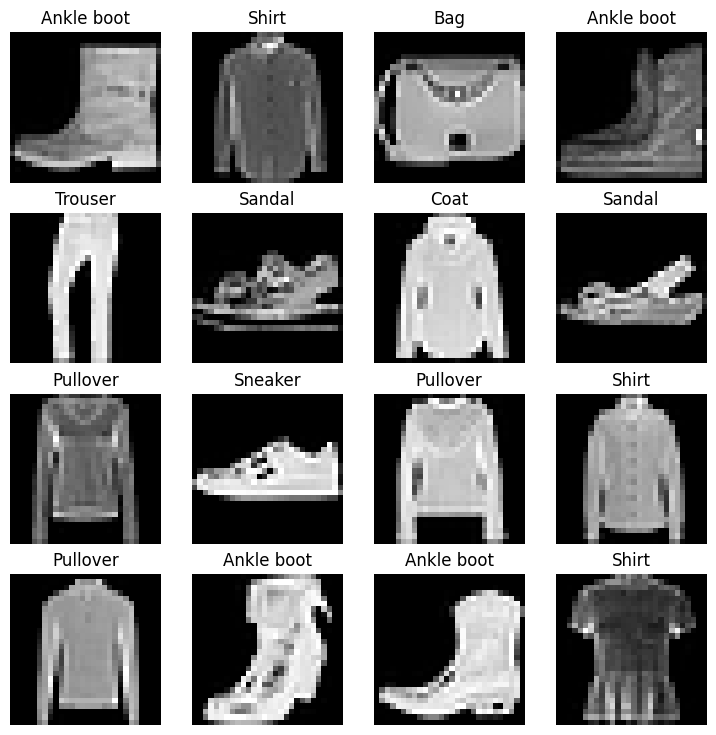

In [ ]:
# Plot more images
torch.manual_seed(42)
fig = plt.figure(figsize=(9, 9))
rows, cols = 4, 4
for i in range(1, rows * cols + 1):
    random_idx = torch.randint(0, len(train_data), size=[1]).item()
    img, label = train_data[random_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze(), cmap="gray")
    plt.title(class_names[label])
    plt.axis(False);

In [ ]:
from torch.utils.data import DataLoader
BATCH_SIZE = 32

In [ ]:
train_dataloader = DataLoader(train_data, # dataset to turn into iterable
    batch_size=BATCH_SIZE, # how many samples per batch?
    shuffle=True # shuffle data every epoch?
)

test_dataloader = DataLoader(test_data,
    batch_size=BATCH_SIZE,
    shuffle=False # don't necessarily have to shuffle the testing data
)

# Let's check out what we've created
print(f"Dataloaders: {train_dataloader, test_dataloader}")
print(f"Length of train dataloader: {len(train_dataloader)} batches of {BATCH_SIZE}")
print(f"Length of test dataloader: {len(test_dataloader)} batches of {BATCH_SIZE}")

Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x787ca90ddd30>, <torch.utils.data.dataloader.DataLoader object at 0x787ca958dc40>)
Length of train dataloader: 1875 batches of 32
Length of test dataloader: 313 batches of 32


In [ ]:
train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape


(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image size: torch.Size([1, 28, 28])
Label: 6, label size: torch.Size([])


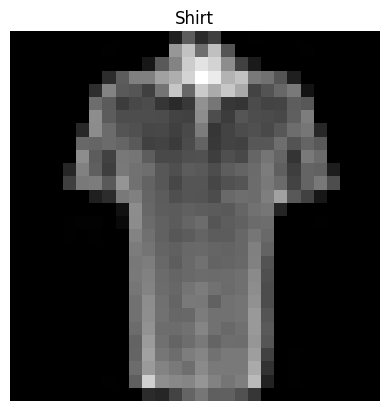

In [ ]:
# Show a sample
torch.manual_seed(42)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()
img, label = train_features_batch[random_idx], train_labels_batch[random_idx]
plt.imshow(img.squeeze(), cmap="gray")
plt.title(class_names[label])
plt.axis("Off");
print(f"Image size: {img.shape}")
print(f"Label: {label}, label size: {label.shape}")

In [ ]:
flatten_model = nn.Flatten()
x = train_features_batch[0]
output = flatten_model(x)
print(f"Shape before flattening: {x.shape} -> [color_channels, height, width]")
print(f"Shape after flattening: {output.shape} -> [color_channels, height*width]")


Shape before flattening: torch.Size([1, 28, 28]) -> [color_channels, height, width]
Shape after flattening: torch.Size([1, 784]) -> [color_channels, height*width]


In [ ]:
print(x)
print(output)

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0039, 0.0039, 0.0000, 0.0000, 0.0078, 0.0078, 0.0000,
          0.0000, 0.0039, 0.0078, 0.0000, 0.0000, 0.0000,

In [ ]:
from torch import nn
class FashionMNISTModelV0(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(), # neural networks like their inputs in vector form
            nn.Linear(in_features=input_shape, out_features=hidden_units), # in_features = number of features in a data sample (784 pixels)
            nn.Linear(in_features=hidden_units, out_features=output_shape)
        )

    def forward(self, x):
        return self.layer_stack(x)

In [ ]:
model_0 = FashionMNISTModelV0(input_shape=784,
                              hidden_units=10,
                              output_shape = len(class_names))

In [ ]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)


In [ ]:
# Import accuracy metric
from helper_functions import accuracy_fn # Note: could also use torchmetrics.Accuracy(task = 'multiclass', num_classes=len(class_names)).to(device)




In [ ]:
from timeit import default_timer as timer
def print_train_time(start: float, end: float, device: torch.device = None):
    total_time = end - start
    print(f"Train time on {device}: {total_time:.3f} seconds")
    return total_time

In [ ]:
# Import tqdm for progress bar
from tqdm.auto import tqdm

# Set the seed and start the timer
torch.manual_seed(42)
train_time_start_on_cpu = timer()

# Set the number of epochs (we'll keep this small for faster training times)
epochs = 3

# Create training and testing loop
for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n-------")
    ### Training
    train_loss = 0
    # Add a loop to loop through training batches
    for batch, (X, y) in enumerate(train_dataloader):
        model_0.train()
        # 1. Forward pass
        y_pred = model_0(X)

        # 2. Calculate loss (per batch)
        loss = loss_fn(y_pred, y)
        train_loss += loss # accumulatively add up the loss per epoch

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

        # Print out how many samples have been seen
        if batch % 400 == 0:
            print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples")

    # Divide total train loss by length of train dataloader (average loss per batch per epoch)
    train_loss /= len(train_dataloader)

    ### Testing
    # Setup variables for accumulatively adding up loss and accuracy
    test_loss, test_acc = 0, 0
    model_0.eval()
    with torch.inference_mode():
        for X, y in test_dataloader:
            # 1. Forward pass
            test_pred = model_0(X)

            # 2. Calculate loss (accumulatively)
            test_loss += loss_fn(test_pred, y) # accumulatively add up the loss per epoch

            # 3. Calculate accuracy (preds need to be same as y_true)
            test_acc += accuracy_fn(y_true=y, y_pred=test_pred.argmax(dim=1))

        # Calculations on test metrics need to happen inside torch.inference_mode()
        # Divide total test loss by length of test dataloader (per batch)
        test_loss /= len(test_dataloader)

        # Divide total accuracy by length of test dataloader (per batch)
        test_acc /= len(test_dataloader)

    ## Print out what's happening
    print(f"\nTrain loss: {train_loss:.5f} | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%\n")

# Calculate training time
train_time_end_on_cpu = timer()
total_train_time_model_0 = print_train_time(start=train_time_start_on_cpu,
                                           end=train_time_end_on_cpu,
                                           device=str(next(model_0.parameters()).device))

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
-------
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples

Train loss: 0.59484 | Test loss: 0.51635, Test acc: 81.84%

Epoch: 1
-------
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples

Train loss: 0.47946 | Test loss: 0.48138, Test acc: 83.18%

Epoch: 2
-------
Looked at 0/60000 samples
Looked at 12800/60000 samples
Looked at 25600/60000 samples
Looked at 38400/60000 samples
Looked at 51200/60000 samples

Train loss: 0.45703 | Test loss: 0.47773, Test acc: 83.50%

Train time on cpu: 27.726 seconds


In [ ]:
torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn):
    """Returns a dictionary containing the results of model predicting on data_loader.

    Args:
        model (torch.nn.Module): A PyTorch model capable of making predictions on data_loader.
        data_loader (torch.utils.data.DataLoader): The target dataset to predict on.
        loss_fn (torch.nn.Module): The loss function of model.
        accuracy_fn: An accuracy function to compare the models predictions to the truth labels.

    Returns:
        (dict): Results of model making predictions on data_loader.
    """
    loss, acc = 0, 0
    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            # Make predictions with the model
            y_pred = model(X)

            # Accumulate the loss and accuracy values per batch
            loss += loss_fn(y_pred, y)
            acc += accuracy_fn(y_true=y,
                                y_pred=y_pred.argmax(dim=1)) # For accuracy, need the prediction labels (logits -> pred_prob -> pred_labels)

        # Scale loss and acc to find the average loss/acc per batch
        loss /= len(data_loader)
        acc /= len(data_loader)

    return {"model_name": model.__class__.__name__, # only works when model was created with a class
            "model_loss": loss.item(),
            "model_acc": acc}

# Calculate model 0 results on test dataset
model_0_results = eval_model(model=model_0, data_loader=test_dataloader,
    loss_fn=loss_fn, accuracy_fn=accuracy_fn
)
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.4777321219444275,
 'model_acc': 83.49640575079871}

In [ ]:
# Setup device agnostic code
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [ ]:
torch.manual_seed(42)
model_1 = FashionMNISTModelV0(input_shape=784, # number of input features
    hidden_units=10,
    output_shape=len(class_names) # number of output classes desired
).to(device) # send model to GPU if it's available
next(model_1.parameters()).device # check model device

device(type='cuda', index=0)

In [ ]:
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_1.parameters(),
                            lr=0.1)

In [ ]:
def train_step(model:torch.nn.Module,
               data_loader:torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               accuracy_fn,
               device: torch.device = device):
  train_loss, train_acc = 0, 0
  model.to(device)
  for batch, (X,y) in enumerate(data_loader):
    X, y = X.to(device), y.to(device)
    y_pred = model(X)

    loss = loss_fn(y_pred, y)
    train_loss += loss
    train_acc += accuracy_fn(y_true= y, y_pred=y_pred.argmax(dim=1))

    optimizer.zero_grad()

        # 4. Loss backward
    loss.backward()

        # 5. Optimizer step
    optimizer.step()
  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f}%")


In [ ]:
def test_step(model:torch.nn.Module,
               data_loader:torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device: torch.device = device):
  test_loss, test_acc = 0, 0
  model.to(device)
  model.eval()

  with torch.inference_mode():
    for X, y in data_loader:
      X, y = X.to(device), y.to(device)
      test_pred = model(X)
      test_loss += loss_fn(test_pred, y)
      test_acc += accuracy_fn(y_true=y,y_pred=test_pred.argmax(dim=1))

    test_loss /= len(data_loader)
    test_acc /= len(data_loader)
    print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%\n")





In [ ]:
# Move values to device
torch.manual_seed(42)
def eval_model(model: torch.nn.Module,
               data_loader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               accuracy_fn,
               device: torch.device = device):
    """Evaluates a given model on a given dataset.

    Args:
        model (torch.nn.Module): A PyTorch model capable of making predictions on data_loader.
        data_loader (torch.utils.data.DataLoader): The target dataset to predict on.
        loss_fn (torch.nn.Module): The loss function of model.
        accuracy_fn: An accuracy function to compare the models predictions to the truth labels.
        device (str, optional): Target device to compute on. Defaults to device.

    Returns:
        (dict): Results of model making predictions on data_loader.
    """
    loss, acc = 0, 0
    model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            # Send data to the target device
            X, y = X.to(device), y.to(device)
            y_pred = model(X)
            loss += loss_fn(y_pred, y)
            acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

        # Scale loss and acc
        loss /= len(data_loader)
        acc /= len(data_loader)
    return {"model_name": model.__class__.__name__, # only works when model was created with a class
            "model_loss": loss.item(),
            "model_acc": acc}

# Calculate model 1 results with device-agnostic code
model_1_results = eval_model(model=model_1, data_loader=test_dataloader,
    loss_fn=loss_fn, accuracy_fn=accuracy_fn,
    device=device
)
model_1_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47143012285232544,
 'model_acc': 83.57627795527156}

In [ ]:
images = torch.randn(size=(32,3,64,64))
test_image = images[0]

print(f"Image batch shape: {images.shape} -> [batch_size, color_channels, height, width]")
print(f"Single image shape: {test_image.shape} -> [color_channels, height, width]")
print(f"Single image pixel values:\n{test_image}")


Image batch shape: torch.Size([32, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Single image shape: torch.Size([3, 64, 64]) -> [color_channels, height, width]
Single image pixel values:
tensor([[[ 0.9007, -2.1055,  0.6784,  ...,  1.3835, -1.2024,  0.7078],
         [ 2.2181,  0.5232,  0.3466,  ...,  0.4114, -0.5733,  0.5069],
         [-1.4364, -1.1299, -0.1360,  ...,  0.7099, -1.5326, -0.7251],
         ...,
         [ 0.4770,  0.1705,  0.8450,  ..., -0.6737,  1.2597, -0.2339],
         [ 0.0366,  0.5164,  0.9172,  ..., -0.8111, -0.1513,  1.4261],
         [-0.7712,  0.6421,  0.6151,  ..., -0.0118,  0.5236, -0.5989]],

        [[ 1.8365,  2.0741, -0.7373,  ..., -0.8515, -0.1488,  0.3166],
         [-1.4277, -0.3318,  1.7054,  ..., -0.4319,  1.7760,  0.4410],
         [-1.9775, -0.0359, -0.7873,  ..., -0.7318, -1.0267, -0.3532],
         ...,
         [-0.3736, -0.3952, -1.2449,  ...,  0.1850, -2.1353, -3.4148],
         [ 0.0937,  1.6574,  1.1300,  ...,  2.2465, -0.4092,

In [ ]:
conv_layer = nn.Conv2d(in_channels=3, out_channels=10, kernel_size=3, stride=1, padding=0)
conv_layer(test_image)

tensor([[[-6.9008e-02,  7.4996e-01, -3.9465e-02,  ..., -2.3797e-01,
           1.0017e+00, -2.1016e-02],
         [ 9.6209e-02, -8.2473e-01,  2.7047e-01,  ..., -4.4110e-01,
          -7.6258e-02,  1.0304e-01],
         [-2.5258e-01, -7.8342e-02, -1.4096e-01,  ...,  3.0379e-01,
          -9.6554e-01,  6.8656e-01],
         ...,
         [-1.2221e-02,  1.7520e-02,  2.5559e-01,  ..., -8.4177e-04,
          -2.8229e-02,  2.1323e-01],
         [ 2.8926e-01,  5.7974e-03,  9.5563e-01,  ..., -1.0714e-01,
          -1.0963e+00,  9.3978e-01],
         [ 4.2720e-01, -8.8833e-01, -1.3444e+00,  ..., -3.5228e-02,
          -5.5466e-01,  4.8906e-01]],

        [[ 5.7091e-01,  2.4147e-01, -3.1261e-01,  ...,  2.2938e-01,
          -8.0416e-01, -7.4030e-02],
         [ 3.9676e-03,  1.4288e-01,  9.5769e-02,  ...,  5.0236e-01,
          -1.1951e+00, -3.9652e-01],
         [-7.5280e-01,  5.5577e-02, -1.3245e-01,  ...,  4.8412e-01,
           3.8948e-01, -1.9265e-02],
         ...,
         [ 2.9946e-01, -4

In [ ]:
# Print out original image shape without and with unsqueezed dimension
print(f"Test image original shape: {test_image.shape}")
print(f"Test image with unsqueezed dimension: {test_image.unsqueeze(dim=0).shape}")

# Create a sample nn.MaxPoo2d() layer
max_pool_layer = nn.MaxPool2d(kernel_size=3)

# Pass data through just the conv_layer
test_image_through_conv = conv_layer(test_image.unsqueeze(dim=0))
print(f"Shape after going through conv_layer(): {test_image_through_conv.shape}")

# Pass data through the max pool layer
test_image_through_conv_and_max_pool = max_pool_layer(test_image_through_conv)
print(f"Shape after going through conv_layer() and max_pool_layer(): {test_image_through_conv_and_max_pool.shape}")

Test image original shape: torch.Size([3, 64, 64])
Test image with unsqueezed dimension: torch.Size([1, 3, 64, 64])
Shape after going through conv_layer(): torch.Size([1, 10, 62, 62])
Shape after going through conv_layer() and max_pool_layer(): torch.Size([1, 10, 20, 20])


In [ ]:
class FashionMNISTModelV2(nn.Module):
  def __init__(self, input_shape, hidden_units, output_shape):
     super().__init__()
     self.block_1 = nn.Sequential(nn.Conv2d(in_channels=input_shape,
                                            out_channels=hidden_units,
                                            kernel_size =3, padding=1),
                    nn.ReLU(),
                    nn.Conv2d(in_channels=hidden_units,
                              out_channels=hidden_units,
                              kernel_size=3,
                              stride=1,
                              padding=1),
                    nn.ReLU(),
                    nn.MaxPool2d(kernel_size=2, stride=2)
                    )
     self.block_2 = nn.Sequential(nn.Conv2d(in_channels=hidden_units,
                                            out_channels=hidden_units,
                                            kernel_size =3, padding=1),
                    nn.ReLU(),
                    nn.Conv2d(in_channels=hidden_units,
                              out_channels=hidden_units,
                              kernel_size=3,
                              stride=1,
                              padding=1),
                    nn.ReLU(),
                    nn.MaxPool2d(kernel_size=2, stride=2)
                    )
     self.classifier = nn.Sequential(nn.Flatten(),
                                     nn.Linear(in_features=hidden_units*7*7,
                                               out_features=output_shape)
                                     )
  def forward(self, x):
      x = self.block_1(x)
      x = self.block_2(x)
      x = self.classifier(x)
      return x

torch.manual_seed(42)
model_2 = FashionMNISTModelV2(input_shape=1, hidden_units=10, output_shape=len(class_names)).to(device)
model_2

FashionMNISTModelV2(
  (block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [ ]:
# Setup loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_2.parameters(),
                             lr=0.1)

In [ ]:
from timeit import default_timer as timer
train_time_start_model_2 = timer()

In [ ]:
epochs = 3
for epoch in tqdm(range(epochs)):
   print(f"Epoch: {epoch}\n---------")
   train_step(model=model_2,
              data_loader=train_dataloader,
              loss_fn=loss_fn,
              optimizer=optimizer,
              accuracy_fn=accuracy_fn,
              device=device)
   test_step(data_loader=test_dataloader,
        model=model_2,
        loss_fn=loss_fn,
        accuracy_fn=accuracy_fn,
        device=device
    )

train_time_end_model_2 = timer()
total_train_time_model_2 = print_train_time(start=train_time_start_model_2,
                                           end=train_time_end_model_2,
                                           device=device)


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
---------
Train loss: 0.57841 | Train accuracy: 79.05%
Test loss: 0.39178 | Test accuracy: 85.47%

Epoch: 1
---------
Train loss: 0.35384 | Train accuracy: 87.29%
Test loss: 0.36038 | Test accuracy: 86.54%

Epoch: 2
---------
Train loss: 0.31590 | Train accuracy: 88.62%
Test loss: 0.33724 | Test accuracy: 87.86%



NameError: name 'print_train_time' is not defined

In [ ]:
def make_predictions(model: torch.nn.Module, data: list, device: torch.device = device):
    pred_probs = []
    model.eval()
    with torch.inference_mode():
        for sample in data:
            # Prepare sample
            sample = torch.unsqueeze(sample, dim=0).to(device) # Add an extra dimension and send sample to device

            # Forward pass (model outputs raw logit)
            pred_logit = model(sample)

            # Get prediction probability (logit -> prediction probability)
            pred_prob = torch.softmax(pred_logit.squeeze(), dim=0) # note: perform softmax on the "logits" dimension, not "batch" dimension (in this case we have a batch size of 1, so can perform on dim=0)

            # Get pred_prob off GPU for further calculations
            pred_probs.append(pred_prob.cpu())

    # Stack the pred_probs to turn list into a tensor
    return torch.stack(pred_probs)

In [ ]:
import random
random.seed(42)
test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k=9):
    test_samples.append(sample)
    test_labels.append(label)

# View the first test sample shape and label
print(f"Test sample image shape: {test_samples[0].shape}\nTest sample label: {test_labels[0]} ({class_names[test_labels[0]]})")

Test sample image shape: torch.Size([1, 28, 28])
Test sample label: 5 (Sandal)


In [ ]:
# Make predictions on test samples with model 2
pred_probs= make_predictions(model=model_2,
                             data=test_samples)

# View first two prediction probabilities list
pred_probs[:2]

tensor([[6.5902e-10, 1.5280e-12, 8.3128e-12, 3.6217e-12, 1.5459e-09, 1.0000e+00,
         2.0644e-08, 3.9105e-09, 5.7017e-08, 2.4488e-06],
        [4.3348e-01, 4.5759e-01, 9.1465e-04, 3.9549e-02, 2.5170e-02, 1.1654e-05,
         4.2957e-02, 6.4421e-05, 2.3407e-04, 2.8655e-05]])

In [ ]:
# Turn the prediction probabilities into prediction labels by taking the argmax()
pred_classes = pred_probs.argmax(dim=1)
pred_classes

tensor([5, 1, 7, 2, 3, 0, 4, 7, 1])

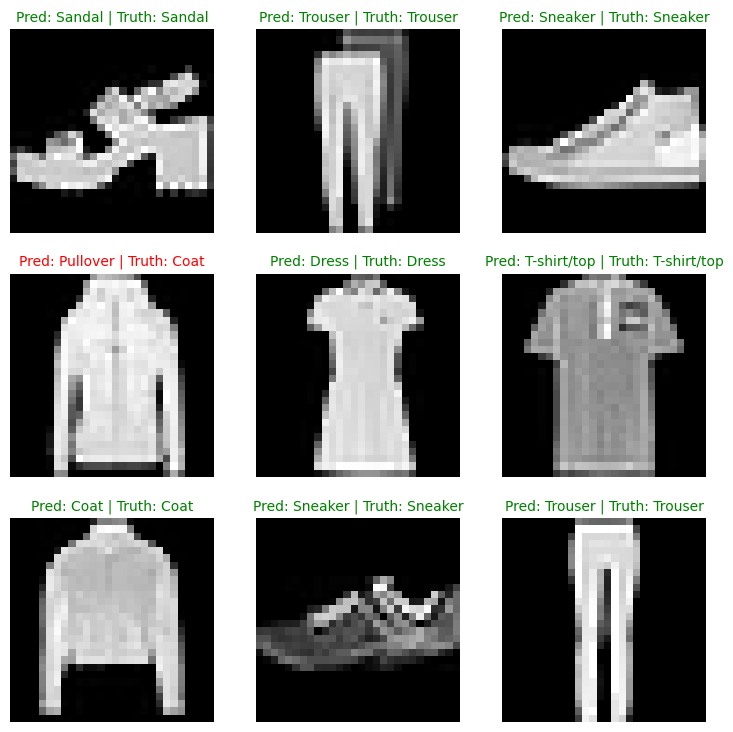

In [ ]:
# Plot predictions
plt.figure(figsize=(9, 9))
nrows = 3
ncols = 3
for i, sample in enumerate(test_samples):
  # Create a subplot
  plt.subplot(nrows, ncols, i+1)

  # Plot the target image
  plt.imshow(sample.squeeze(), cmap="gray")

  # Find the prediction label (in text form, e.g. "Sandal")
  pred_label = class_names[pred_classes[i]]

  # Get the truth label (in text form, e.g. "T-shirt")
  truth_label = class_names[test_labels[i]]

  # Create the title text of the plot
  title_text = f"Pred: {pred_label} | Truth: {truth_label}"

  # Check for equality and change title colour accordingly
  if pred_label == truth_label:
      plt.title(title_text, fontsize=10, c="g") # green text if correct
  else:
      plt.title(title_text, fontsize=10, c="r") # red text if wrong
  plt.axis(False);

In [ ]:
# Import tqdm for progress bar
from tqdm.auto import tqdm

# 1. Make predictions with trained model
y_preds = []
model_2.eval()
with torch.inference_mode():
  for X, y in tqdm(test_dataloader, desc="Making predictions"):
    # Send data and targets to target device
    X, y = X.to(device), y.to(device)
    # Do the forward pass
    y_logit = model_2(X)
    # Turn predictions from logits -> prediction probabilities -> predictions labels
    y_pred = torch.softmax(y_logit, dim=1).argmax(dim=1) # note: perform softmax on the "logits" dimension, not "batch" dimension (in this case we have a batch size of 32, so can perform on dim=1)
    # Put predictions on CPU for evaluation
    y_preds.append(y_pred.cpu())
# Concatenate list of predictions into a tensor
y_pred_tensor = torch.cat(y_preds)

Making predictions:   0%|          | 0/313 [00:00<?, ?it/s]

In [ ]:
!pip install -q torchmetrics -U mlxtend

In [ ]:
import torchmetrics, mlxtend

In [ ]:
pip install --upgrade torchmetrics mlxtend


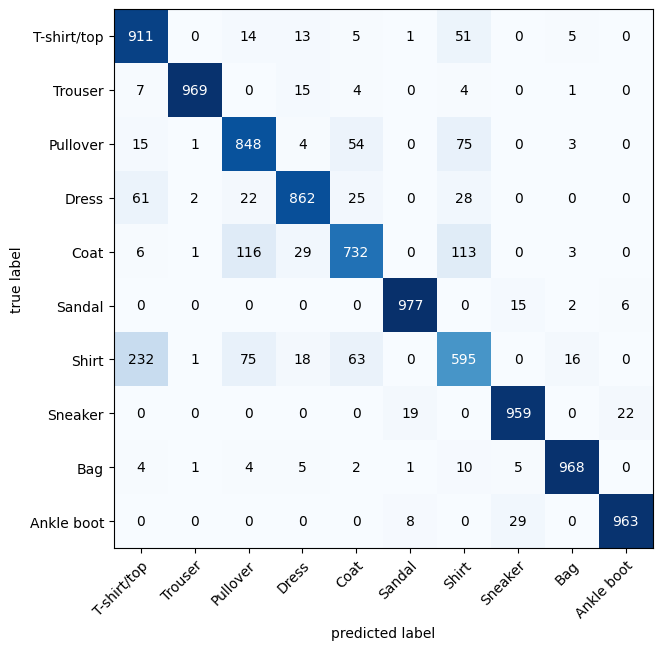

In [ ]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

matrix = ConfusionMatrix(num_classes=len(class_names), task='multiclass')
confmat_tensor = matrix(preds=y_pred_tensor, target=test_data.targets)

fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(), # matplotlib likes working with NumPy
    class_names=class_names, # turn the row and column labels into class names
    figsize=(10, 7)
);


ДЗ


In [ ]:
import torch
import torchvision
from torch import nn
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader

In [ ]:
train_data = MNIST(root='data', download=True, train=True, transform=ToTensor() )
test_data = MNIST(root='data', download=True, train=False, transform=ToTensor() )

In [ ]:
train_data, test_data

(Dataset MNIST
     Number of datapoints: 60000
     Root location: data
     Split: Train
     StandardTransform
 Transform: ToTensor(),
 Dataset MNIST
     Number of datapoints: 10000
     Root location: data
     Split: Test
     StandardTransform
 Transform: ToTensor())

In [ ]:
image, label = train_data[0]


5

In [ ]:
image.shape

torch.Size([1, 28, 28])

In [ ]:
BATCH_SIZE = 32
train_dataloader = DataLoader(dataset=train_data, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(dataset=test_data, batch_size=BATCH_SIZE, shuffle=False)
len(train_dataloader), len(test_dataloader)

(1875, 313)

In [ ]:
train_f_b, train_l_b = next(iter(train_dataloader))
train_f_b.shape, train_l_b.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

4354
43087
54932
59545
2426
23149
21475
54649
26119
29028
42545
36171
51368
51829
20236
11461
12346
58522
39254
11300


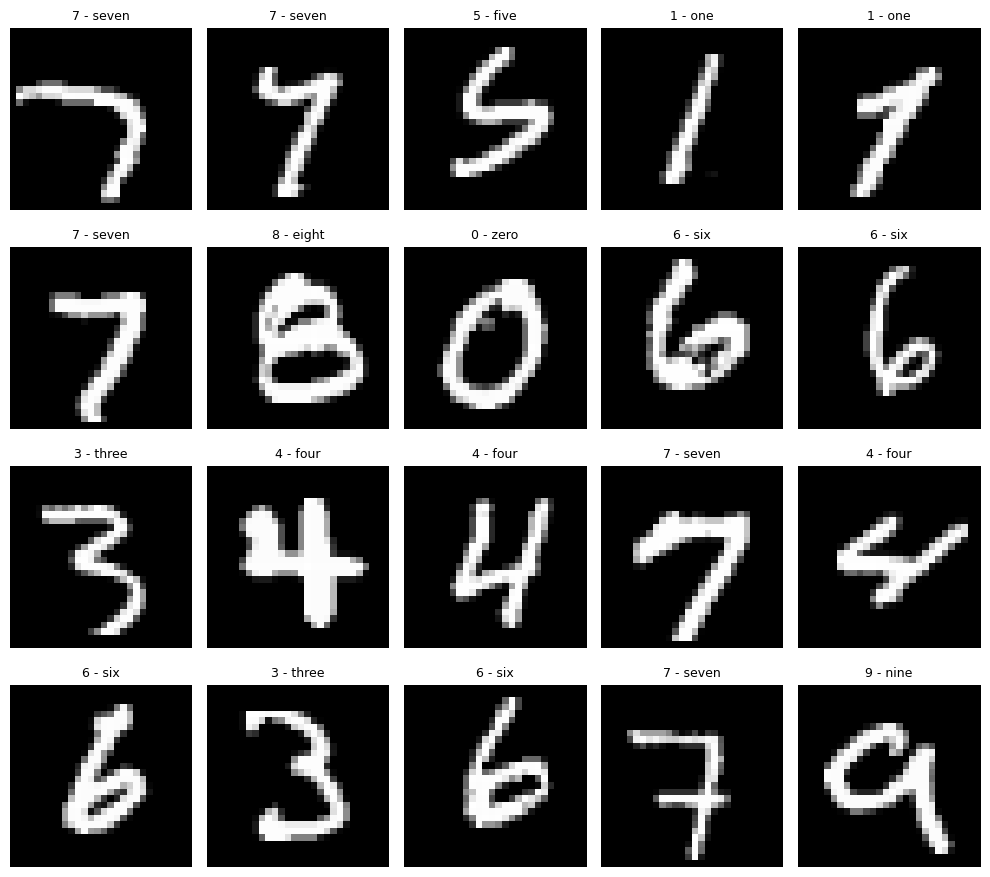

In [ ]:
import matplotlib.pyplot as plt

name_classes = train_data.classes

rows, col = 4, 5
plt.figure(figsize = (10,9))
torch.manual_seed(42)
for i in range(1, rows*col+1):
  random_idx = torch.randint(1, len(train_data), size=(1,)).item()
  print(random_idx)
  image, label = train_data[random_idx]
  plt.subplot(rows, col, i)
  plt.imshow(image.squeeze(), cmap="gray")
  plt.title(name_classes[label], fontsize=9)
  plt.axis(False)

plt.tight_layout()
plt.show()



In [ ]:
class ModelMNIST(nn.Module):
  def __init__(self, input_shape, hidden_units, output_shape):
     super().__init__()
     self.layer1 = nn.Sequential(
         nn.Conv2d(in_channels=input_shape,
                   out_channels=hidden_units,
                   kernel_size=4,
                   padding=1,
                   stride =1),
         nn.ReLU(),
         nn.Conv2d(in_channels=hidden_units,
                   out_channels=hidden_units,
                   kernel_size=4,
                   padding=1,
                   stride =1),
         nn.ReLU(),
         nn.MaxPool2d(kernel_size=2)
)
     self.layer2 = nn.Sequential(
         nn.Conv2d(in_channels=hidden_units,
                   out_channels=hidden_units,
                   kernel_size=4,
                   padding=1,
                   stride =1),
         nn.ReLU(),
         nn.Conv2d(in_channels=hidden_units,
                   out_channels=hidden_units,
                   kernel_size=4,
                   padding=1,
                   stride =1),
         nn.ReLU(),
         nn.MaxPool2d(kernel_size=2)
     )
     self.classifier = nn.Sequential(
         nn.Flatten(),
         nn.Linear(in_features=hidden_units*5*5, out_features=output_shape)
     )
  def forward(self, x):
    x = self.layer1(x)
    # print(f"Output shape of conv block 1: {x.shape}")
    x = self.layer2(x)
    # print(f"Output shape of conv block 2: {x.shape}")
    x = self.classifier(x)
    # print(f"Output shape of classifier: {x.shape}")
    return x


In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [ ]:
model = ModelMNIST(input_shape=1,
                    hidden_units=10,
                    output_shape=10).to(device)
model


ModelMNIST(
  (layer1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(4, 4), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(4, 4), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(4, 4), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(4, 4), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=250, out_features=10, bias=True)
  )
)

In [ ]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

helper_functions.py already exists, skipping download


In [ ]:
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)


In [ ]:
def train_step(model,
               data_loader,
               loss_fn,
               accuracy_fn,
               optimizer,
               device):
  train_loss, train_acc = 0 , 0
  model.to(device)
  for batch, (X, y) in enumerate(data_loader):
    X, y = X.to(device), y.to(device)
    y_pred = model(X)
    loss = loss_fn(y_pred, y)
    train_loss += loss
    train_acc += accuracy_fn(y_true=y, y_pred= y_pred.argmax(dim=1))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  train_loss /= len(data_loader)
  train_acc /= len(data_loader)
  print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f}%")






In [ ]:
def test_step(model,
               data_loader,
               loss_fn,
               accuracy_fn,
               device):
  test_loss, test_acc = 0 , 0
  model.to(device)
  model.eval()
  with torch.inference_mode():
    for X, y in data_loader:
      X, y = X.to(device), y.to(device)
      test_pred = model(X)
      test_loss += loss_fn(test_pred, y)
      test_acc += accuracy_fn(y_true=y,
                              y_pred=test_pred.argmax(dim=1) # Go from logits -> pred labels
            )

        # Adjust metrics and print out
    test_loss /= len(data_loader)
    test_acc /= len(data_loader)
    print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%\n")


In [ ]:
torch.manual_seed(42)
epochs = 3
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n---------")
    train_step(data_loader=train_dataloader,
        model=model,
        loss_fn=loss_fn,
        optimizer=optimizer,
        accuracy_fn=accuracy_fn,
        device=device
    )
    test_step(data_loader=test_dataloader,
        model=model,
        loss_fn=loss_fn,
        accuracy_fn=accuracy_fn,
        device=device
    )

Epoch: 0
---------
Train loss: 0.02997 | Train accuracy: 99.04%
Test loss: 0.03889 | Test accuracy: 98.81%

Epoch: 1
---------
Train loss: 0.02857 | Train accuracy: 99.12%
Test loss: 0.03733 | Test accuracy: 98.83%

Epoch: 2
---------
Train loss: 0.02715 | Train accuracy: 99.11%
Test loss: 0.03707 | Test accuracy: 98.79%

